# Credit card fraud detection: results

This notebook reads the reports written by `make pipeline` (it doesn't need the raw data). All numbers are on the untouched `fraudTest.csv` (555,719 transactions, Jun–Dec 2020). Decision thresholds were tuned on a time-based validation split of `fraudTrain.csv`.

Error-rate definitions: **Type II error rate** = missed frauds / all frauds (= 1 − recall); **missed frauds / all transactions** = FN / N; **Type I error rate** = false alarms / legitimate transactions.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.float_format', '{:.4f}'.format)
comparison = pd.read_csv('model_comparison.csv')
comparison

,model,threshold,f1,precision,recall,roc_auc,pr_auc,type_ii_error_rate,missed_fraud_share_of_all,type_i_error_rate,fn,fp
0,logistic_regression,0.7610,0.5547,0.5250,0.5879,0.9653,0.3760,0.4121,0.0016,0.0021,884,1141
1,random_forest,0.4570,0.8912,0.9150,0.8685,0.9978,0.9442,0.1315,0.0005,0.0003,282,173
2,xgboost,0.3590,0.9327,0.9591,0.9077,0.9994,0.9733,0.0923,0.0004,0.0001,198,83


## Selected model

In [2]:
report = json.load(open('model_comparison.json'))
best = report['selected_model']
r = report['results'][best]
print('Selected:', best)
print('Hyperparameters:', r['best_params'])
pd.DataFrame({'validation': r['validation'], 'test': r['test']})

Selected: xgboost
Hyperparameters: {'n_estimators': 600, 'max_depth': 8, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 3, 'reg_lambda': 5.0, 'sampler': 'none'}


,validation,test
threshold,0.3588,0.3588
f1,0.9542,0.9327
precision,0.9615,0.9591
recall,0.9470,0.9077
roc_auc,0.9997,0.9994
pr_auc,0.9834,0.9733
type_ii_error_rate,0.0530,0.0923
missed_fraud_share_of_all,0.0003,0.0004
type_i_error_rate,0.0002,0.0001
tp,1073.0000,1947.0000


## Hyperparameter search (validation PR-AUC)

In [3]:
pd.DataFrame([{'model': m, 'params': t['params'], 'val_pr_auc': t['val_pr_auc'], 'seconds': t['seconds']}
              for m, res in report['results'].items() for t in res['tuning_trials']])

,model,params,val_pr_auc,seconds
0,logistic_regression,{'C': 0.1},0.4877,0.9000
1,logistic_regression,{'C': 1.0},0.4873,0.9000
2,logistic_regression,"{'C': 1.0, 'sampler': 'none', 'class_weight': ...",0.3713,1.0000
3,random_forest,"{'n_estimators': 150, 'max_depth': 16, 'min_sa...",0.9548,56.3000
4,random_forest,"{'n_estimators': 150, 'max_depth': 24, 'min_sa...",0.9604,54.5000
5,xgboost,"{'n_estimators': 400, 'max_depth': 6, 'learnin...",0.9815,6.8000
6,xgboost,"{'n_estimators': 600, 'max_depth': 8, 'learnin...",0.9829,12.8000
7,xgboost,"{'n_estimators': 400, 'max_depth': 6, 'learnin...",0.9807,8.8000


## ROC and precision-recall curves

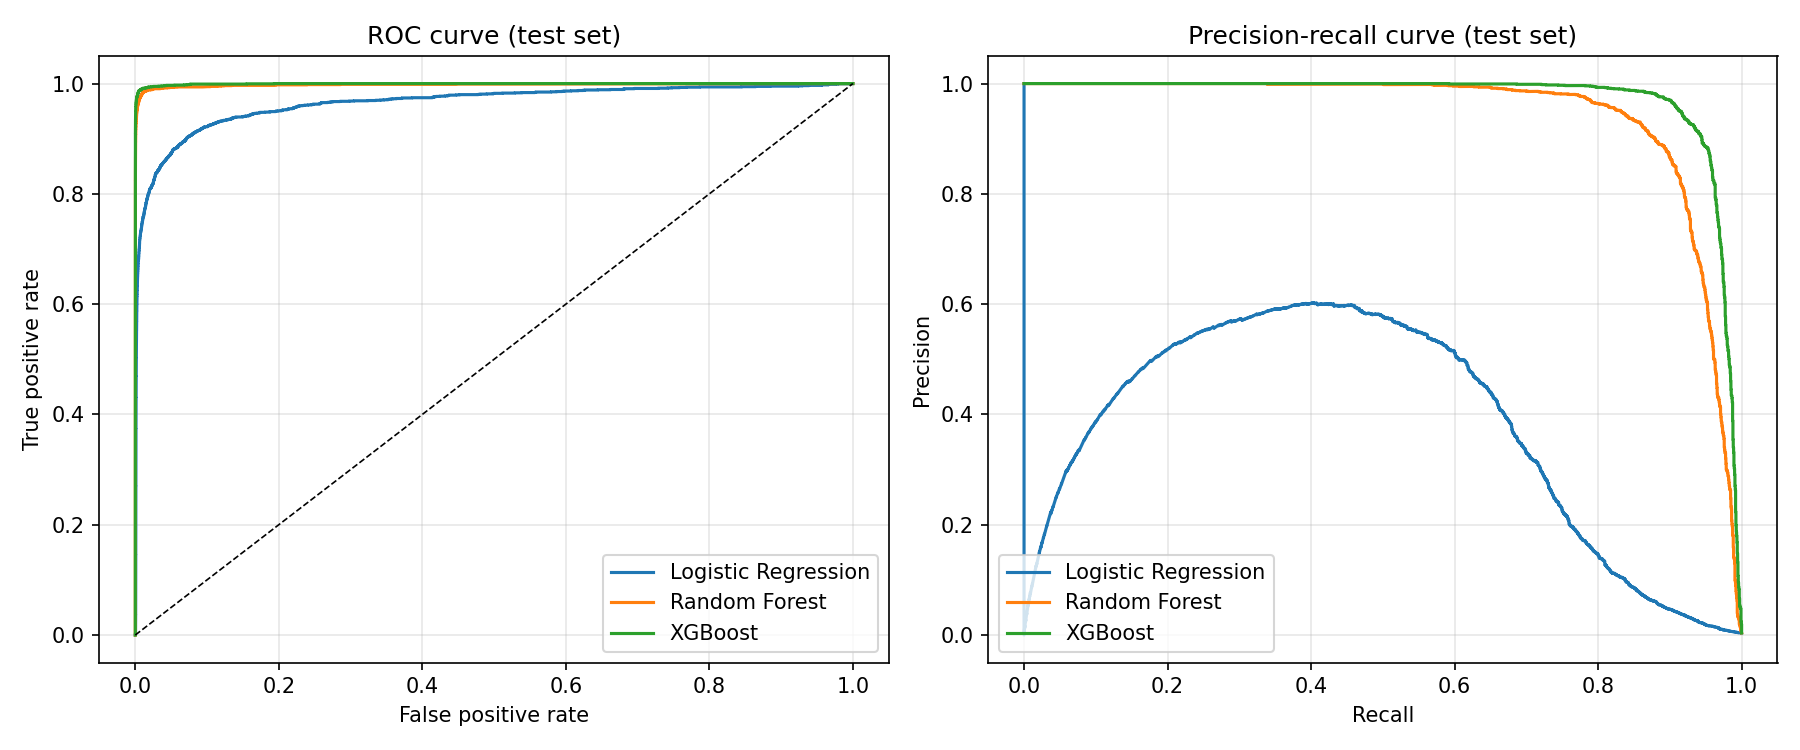

In [4]:
display(Image('figures/roc_pr_curves.png'))

## Confusion matrix and feature importance

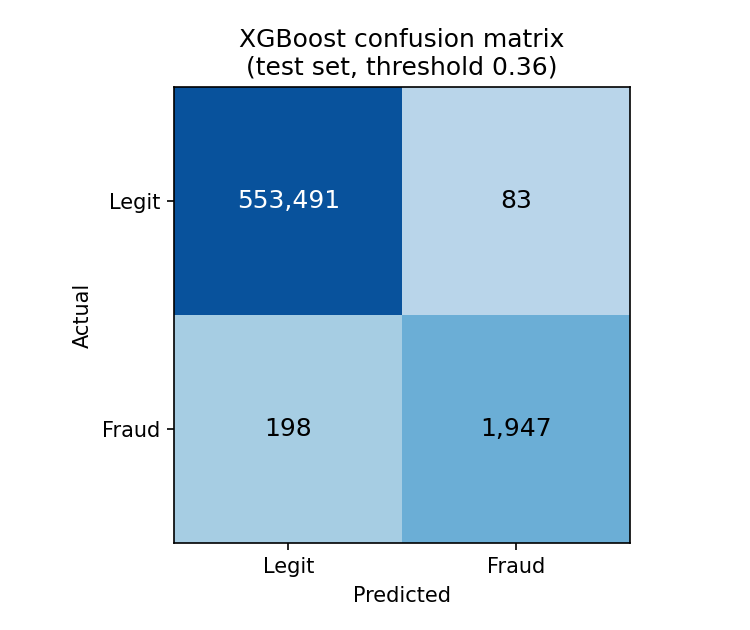

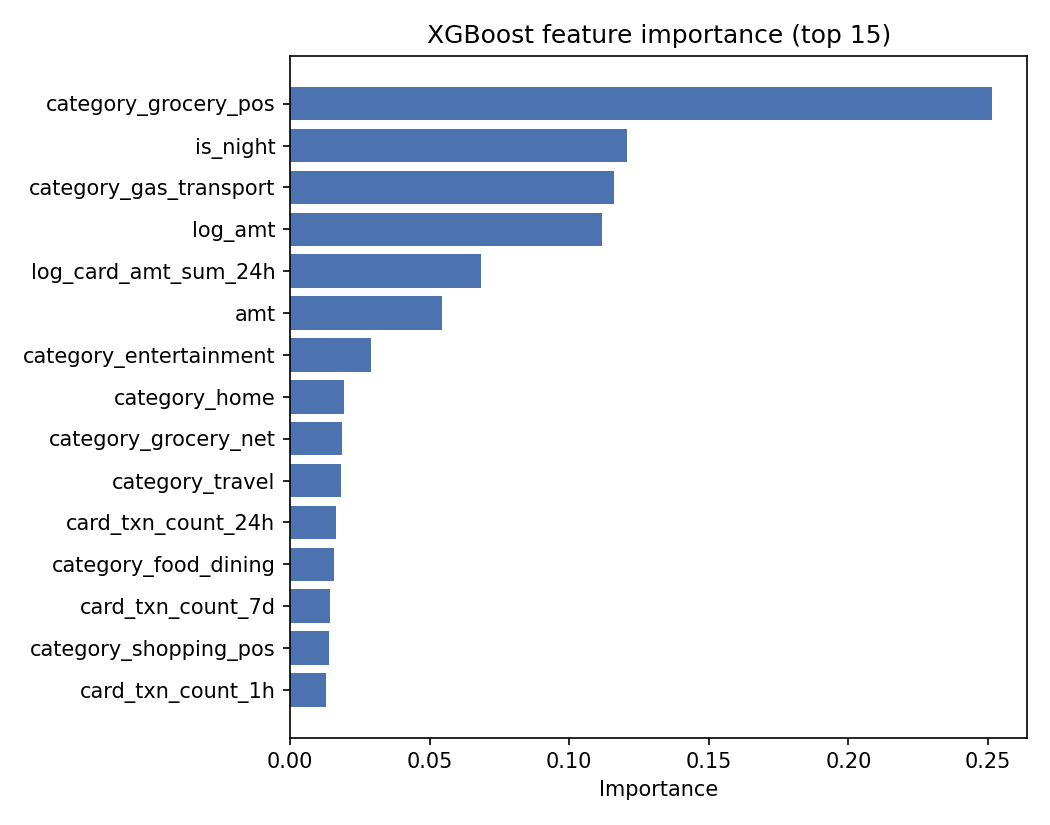

In [5]:
display(Image('figures/confusion_matrix.png'))
display(Image('figures/feature_importance.png'))

## Monitoring: month-by-month replay of the test period

Alerts fire when recall drops more than 5 points below validation or any feature's PSI exceeds 0.2.

,month,transactions,frauds,f1,precision,recall,type_ii_error_rate,max_feature_psi,max_psi_feature,alerts
0,2020-06,30058,133,0.9615,0.9843,0.9398,0.0602,0.2185,dow_cos,PSI dow_cos=0.22
1,2020-07,85848,321,0.9241,0.9597,0.8910,0.1090,0.0769,card_txn_count_7d,recall 0.891 < validation 0.947 - 0.05
2,2020-08,88759,415,0.9407,0.9646,0.9181,0.0819,0.0691,card_txn_count_7d,none
3,2020-09,69533,340,0.9364,0.9656,0.9088,0.0912,0.0729,dow_sin,none
4,2020-10,69348,384,0.9344,0.9614,0.9089,0.0911,0.0912,card_txn_count_7d,none
5,2020-11,72635,294,0.9331,0.9412,0.9252,0.0748,0.0877,card_txn_count_7d,none
6,2020-12,139538,258,0.9073,0.9454,0.8721,0.1279,1.0459,card_txn_count_7d,recall 0.872 < validation 0.947 - 0.05; PSI ca...


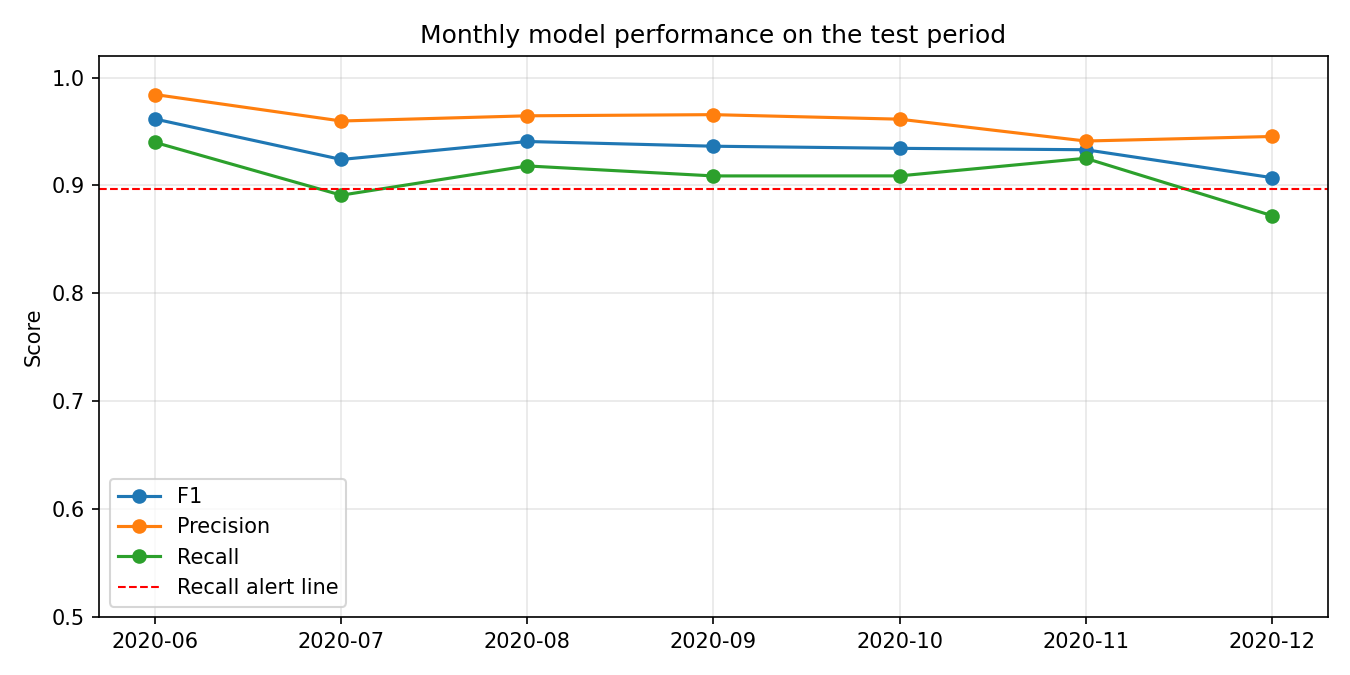

In [6]:
monthly = pd.read_csv('monitoring/monthly_performance.csv')
display(monthly)
display(Image('monitoring/monthly_performance.png'))